# Customer Churn Prediction

This notebook explores the Telco customer dataset and compares two simple models for identifying customers who may churn.

## Business problem

Customer churn happens when a customer stops using a company's service. Churn can reduce recurring revenue and increase the effort needed to replace customers. A business may use historical customer information to identify patterns and decide which customers could benefit from timely, appropriate support. The analysis below describes associations in this dataset; it does not establish why any customer leaves.

## Import the libraries

Pandas and NumPy help work with tables and numbers. Matplotlib and seaborn create charts. Scikit-learn provides the data splitting, preprocessing, models, and evaluation measures.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

C:\Users\PC\anaconda3\anaconda2\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


## Load the dataset

The path is resolved from either the project folder or its `notebooks` folder. If the expected CSV is not present, the code stops with a clear error rather than substituting another dataset.

In [2]:
project_root = Path.cwd()
dataset_path = project_root / "data" / "raw" / "Telco-Customer-Churn.csv"

if not dataset_path.is_file():
    project_root = project_root.parent
    dataset_path = project_root / "data" / "raw" / "Telco-Customer-Churn.csv"

if not dataset_path.is_file():
    raise FileNotFoundError(
        "Could not find data/raw/Telco-Customer-Churn.csv from the project "
        "folder or the notebooks folder."
    )

df = pd.read_csv(dataset_path)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {dataset_path}")

Loaded 7,043 rows and 21 columns from C:\Users\PC\Documents\Customer-Churn-Prediction\data\raw\Telco-Customer-Churn.csv


## First look at the data

These views show sample records, the dataset dimensions, column names, data types, and summary statistics. Summary statistics for categorical fields are included as well as numeric fields.

In [3]:
display(df.head())
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame(name="Data type"))
print("Summary statistics:")
display(df.describe(include="all").T)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)
Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,Data type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Check data quality

This checks missing values and exact duplicate rows before cleaning. An identifier such as `customerID` is allowed to be unique; duplicate rows here means every column matches.

In [4]:
print("Missing values by column:")
display(df.isna().sum().to_frame(name="Missing values"))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print("TotalCharges values that are blank or whitespace only:",
      df["TotalCharges"].astype("string").str.strip().eq("").sum())

Missing values by column:


,Missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Exact duplicate rows: 0


TotalCharges values that are blank or whitespace only: 11


## Clean `TotalCharges`

Some `TotalCharges` entries may contain only whitespace. Those entries are not valid numeric values, so they are changed to missing values before numeric conversion. The notebook reports how many values are affected and keeps the rows; later, the training-only median imputer will handle these missing numeric values.

In [5]:
blank_total_charges = df["TotalCharges"].astype("string").str.strip().eq("").sum()
missing_total_charges_before = df["TotalCharges"].isna().sum()
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce",
)
missing_total_charges_after = df["TotalCharges"].isna().sum()

print(f"Blank or whitespace-only entries found: {blank_total_charges:,}")
print(f"Missing values before conversion: {missing_total_charges_before:,}")
print(f"Missing values after numeric conversion: {missing_total_charges_after:,}")
print("TotalCharges data type:", df["TotalCharges"].dtype)

Blank or whitespace-only entries found: 11
Missing values before conversion: 0
Missing values after numeric conversion: 11
TotalCharges data type: float64


## Explore the target: `Churn`

Counts and percentages show how many customers did and did not churn. This also helps us see whether the target classes are imbalanced.

In [6]:
churn_counts = df["Churn"].value_counts(dropna=False)
churn_percentages = df["Churn"].value_counts(normalize=True, dropna=False).mul(100)
churn_summary = pd.DataFrame({"Customers": churn_counts, "Percent": churn_percentages})
display(churn_summary)

,Customers,Percent
Churn,,
No,5174,73.463013
Yes,1869,26.536987


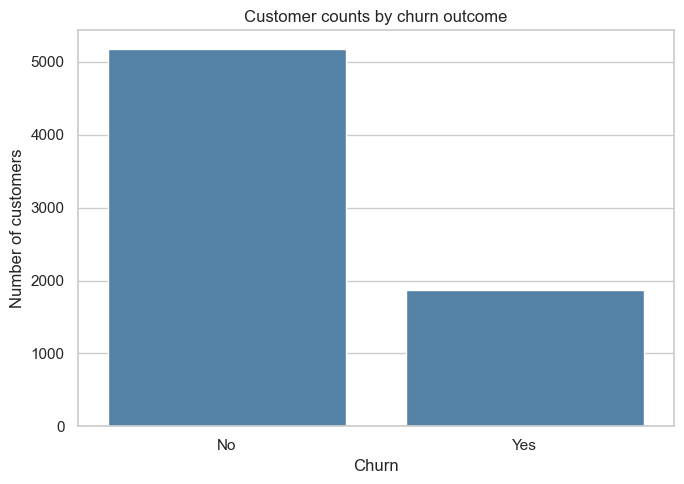

In [7]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], color="steelblue")
plt.title("Customer counts by churn outcome")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## Churn rates across customer groups

The charts compare the share of customers marked as churned within each Contract, InternetService, PaymentMethod, and SeniorCitizen group. A rate is more useful than raw counts for comparing groups of different sizes. These are descriptive comparisons, not causal effects.

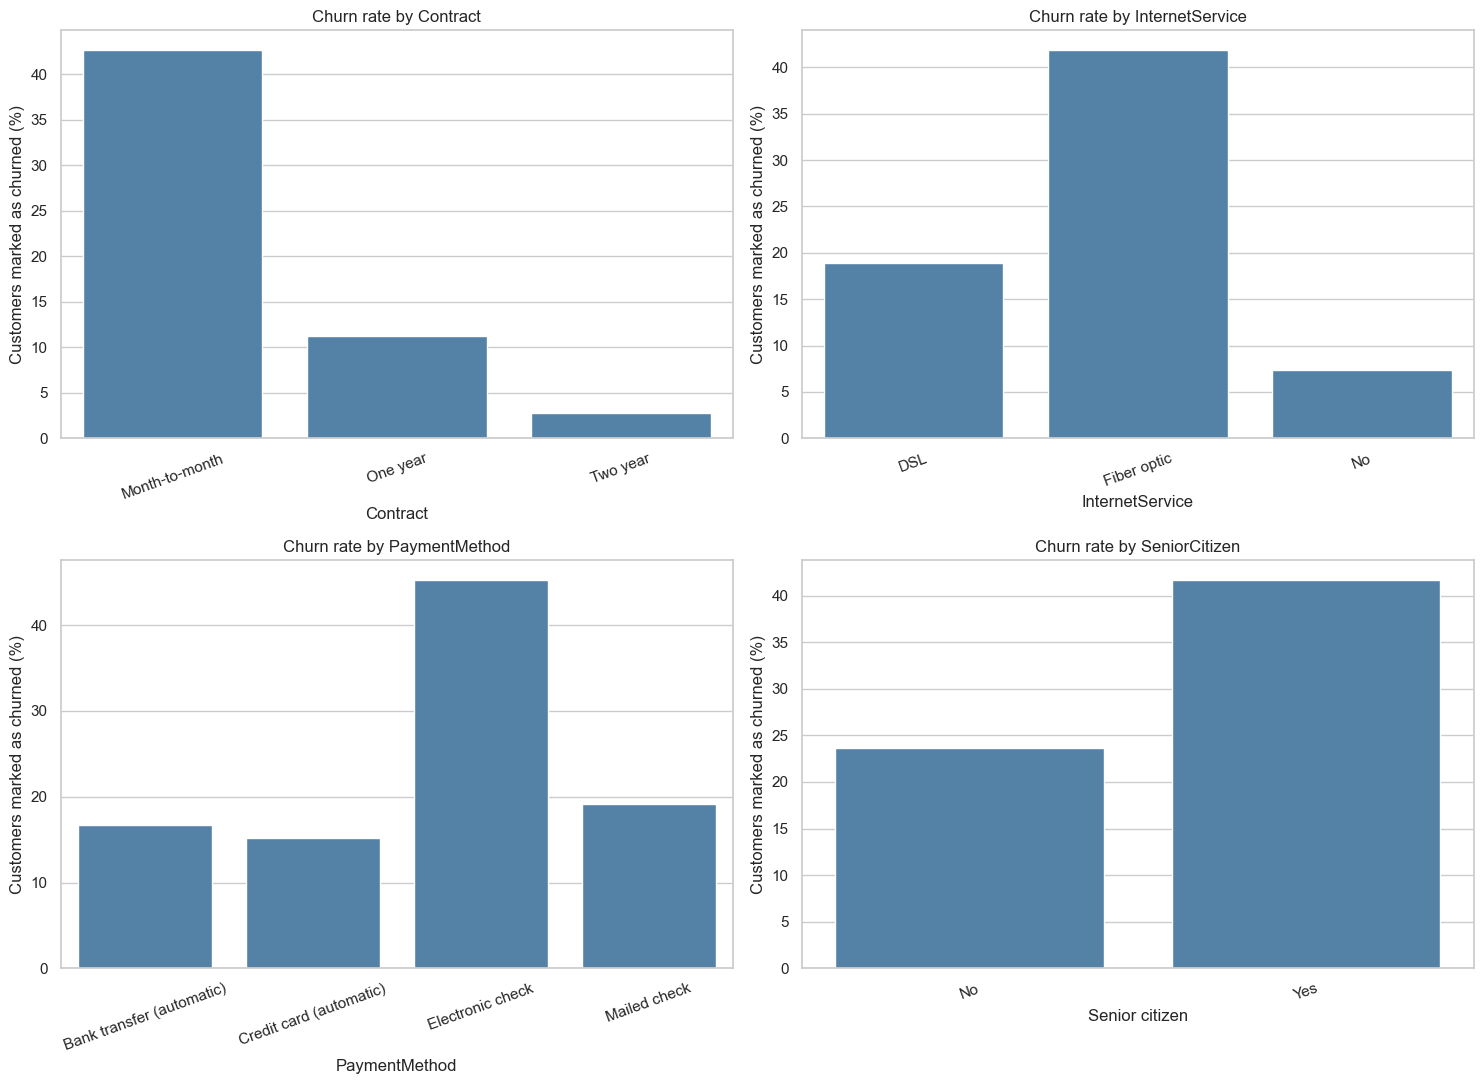

In [8]:
category_columns = ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]
df["ChurnFlag"] = df["Churn"].eq("Yes").astype(int)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for column, ax in zip(category_columns, axes.flat):
    rate_data = (
        df.groupby(column, dropna=False)["ChurnFlag"]
        .mean()
        .mul(100)
        .rename("Churn rate")
        .reset_index()
    )
    if column == "SeniorCitizen":
        rate_data[column] = rate_data[column].map({0: "No", 1: "Yes"})
    sns.barplot(data=rate_data, x=column, y="Churn rate", color="steelblue", ax=ax)
    ax.set_title(f"Churn rate by {column}")
    ax.set_xlabel(column if column != "SeniorCitizen" else "Senior citizen")
    ax.set_ylabel("Customers marked as churned (%)")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Tenure and monthly charges by churn

Box plots show the distributions and medians for tenure and monthly charges. The boxes summarize the middle half of the values; individual extremes are not shown.

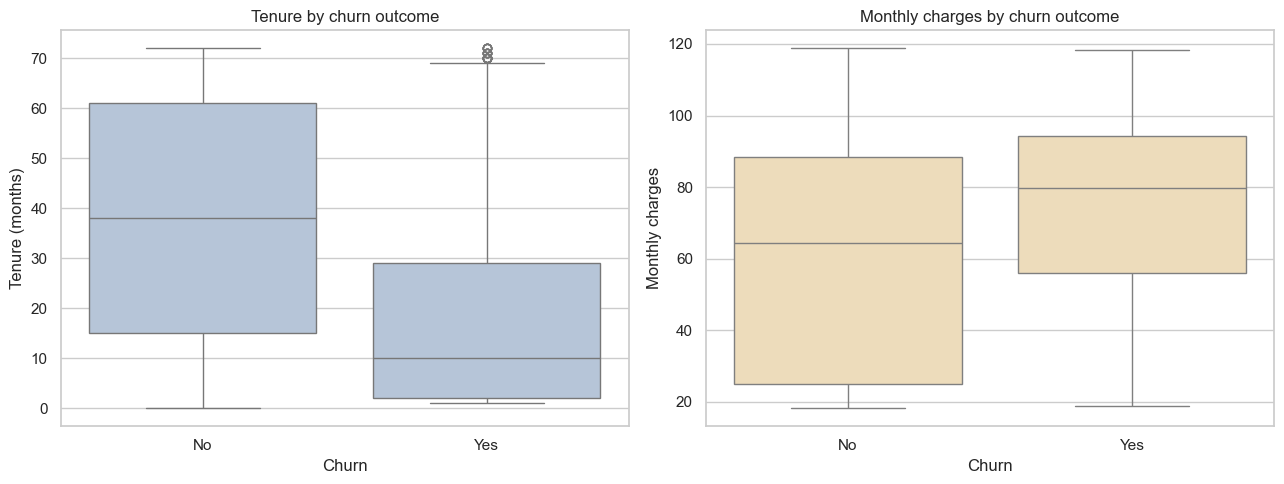

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="Churn", y="tenure", order=["No", "Yes"], color="lightsteelblue", ax=axes[0])
axes[0].set_title("Tenure by churn outcome")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], color="wheat", ax=axes[1])
axes[1].set_title("Monthly charges by churn outcome")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly charges")
plt.tight_layout()
plt.show()

## Correlation between numeric variables

The heatmap shows pairwise correlations among numeric columns and a numeric version of Churn. Correlation describes a linear association and does not show that one variable causes another.

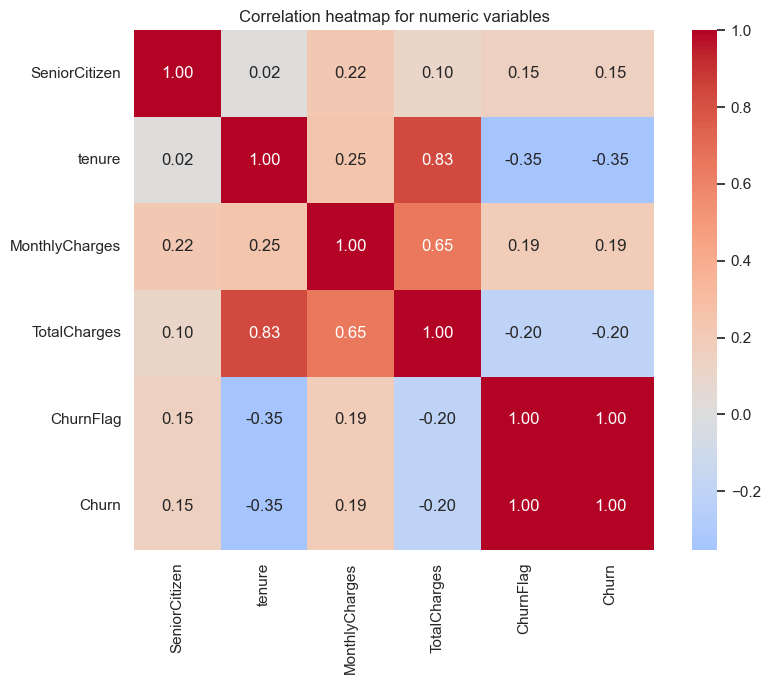

In [10]:
numeric_for_correlation = df.select_dtypes(include="number").copy()
numeric_for_correlation["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
correlation = numeric_for_correlation.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap for numeric variables")
plt.tight_layout()
plt.show()

## Descriptive findings

The table below calculates churn rates and average tenure and monthly charges directly from the loaded CSV. Use these observed patterns as a description of this sample, not as evidence that a contract or charge causes churn.

In [11]:
contract_churn_rates = (
    df.groupby("Contract")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
)
internet_churn_rates = (
    df.groupby("InternetService")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
)
payment_churn_rates = (
    df.groupby("PaymentMethod")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
)
senior_churn_rates = df.groupby("SeniorCitizen")["ChurnFlag"].mean().mul(100)
average_by_churn = df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean()

print("Churn rate by contract (%):")
display(contract_churn_rates.rename("Churn rate (%)").to_frame())
print("Churn rate by internet service (%):")
display(internet_churn_rates.rename("Churn rate (%)").to_frame())
print("Churn rate by payment method (%):")
display(payment_churn_rates.rename("Churn rate (%)").to_frame())
print("Churn rate by SeniorCitizen (0 = No, 1 = Yes; %):")
display(senior_churn_rates.rename("Churn rate (%)").to_frame())
print("Average tenure and monthly charges by churn outcome:")
display(average_by_churn)

Churn rate by contract (%):


,Churn rate (%)
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


Churn rate by internet service (%):


,Churn rate (%)
InternetService,
Fiber optic,41.892765
DSL,18.959108
No,7.404980


Churn rate by payment method (%):


,Churn rate (%)
PaymentMethod,
Electronic check,45.285412
Mailed check,19.106700
Bank transfer (automatic),16.709845
Credit card (automatic),15.243101


Churn rate by SeniorCitizen (0 = No, 1 = Yes; %):


,Churn rate (%)
SeniorCitizen,
0,23.606168
1,41.681261


Average tenure and monthly charges by churn outcome:


,tenure,MonthlyCharges
Churn,,
No,37.569965,61.265124
Yes,17.979133,74.441332


## Prepare features and target

The target is encoded as 1 for `Yes` and 0 for `No`. `customerID` is removed because it identifies a row rather than describing customer behavior. The stratified 80/20 split keeps the churn proportion similar in the training and test sets. The test set is held aside until evaluation.

In [12]:
model_data = df.drop(columns="ChurnFlag").copy()
model_data["Churn"] = model_data["Churn"].map({"No": 0, "Yes": 1})

X = model_data.drop(columns=["Churn", "customerID"])
y = model_data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"Churn share in training data: {y_train.mean():.1%}")
print(f"Churn share in testing data: {y_test.mean():.1%}")

Training rows: 5,634
Testing rows: 1,409
Churn share in training data: 26.5%
Churn share in testing data: 26.5%


## Preprocess numeric and categorical features

Numeric missing values are filled with the median and then scaled; scaling puts numeric measurements on comparable ranges, which can help logistic regression. Categorical missing values use the most frequent value. One-hot encoding turns categories into numeric indicator columns and ignores categories not seen during training. A `ColumnTransformer` applies the right steps to each column group. Keeping preprocessing inside each model pipeline ensures it is fitted only on training data, which helps prevent test-data leakage.

In [13]:
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_columns),
        ("categorical", categorical_preprocessor, categorical_columns),
    ]
)

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Train two classification models

Logistic regression is a common, relatively simple classification baseline. A random forest combines many decision trees. Both use `class_weight="balanced"` so the less common churn class receives more weight during training. The pipelines keep preprocessing and model fitting together; the random states make the split and forest reproducible.

In [14]:
logistic_regression_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

models = {
    "Logistic Regression": logistic_regression_pipeline,
    "Random Forest": random_forest_pipeline,
}

In [15]:
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Finished training {model_name}.")

Finished training Logistic Regression.


Finished training Random Forest.


## Evaluate on the held-out test data

Accuracy is the share of all predictions that are correct, but it can hide poor detection of a less common class. Precision asks how many predicted churners actually churned; recall asks how many actual churners were found. F1 balances precision and recall. ROC-AUC measures how well scores rank the two classes across thresholds. Each model also gets a confusion matrix and classification report.

Logistic Regression classification report


              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Random Forest classification report
              precision    recall  f1-score   support

    No churn       0.82      0.90      0.86      1035
       Churn       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



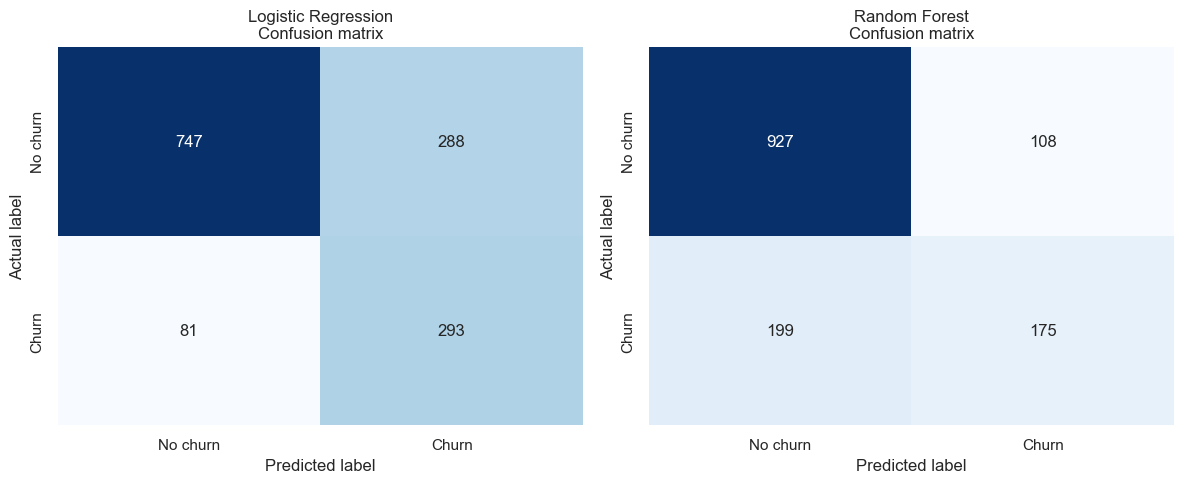

In [16]:
metrics_rows = []
fig, axes = plt.subplots(1, len(models), figsize=(12, 5))

for (model_name, model), ax in zip(models.items(), axes):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    metrics_rows.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1-score": f1_score(y_test, predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, probabilities),
        }
    )

    print(f"{model_name} classification report")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["No churn", "Churn"],
            zero_division=0,
        )
    )
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No churn", "Churn"],
        yticklabels=["No churn", "Churn"],
        ax=ax,
    )
    ax.set_title(f"{model_name}\nConfusion matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

results_table = pd.DataFrame(metrics_rows).set_index("Model")

In [17]:
print("Model comparison on the same held-out test set:")
display(results_table.round(3))

Model comparison on the same held-out test set:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.841
Random Forest,0.782,0.618,0.468,0.533,0.819


## Compare ROC curves

Both classifiers provide predicted probabilities, so their ROC curves can be compared on the same test data. A curve closer to the upper-left generally indicates better separation across thresholds; the diagonal is a reference for random ranking.

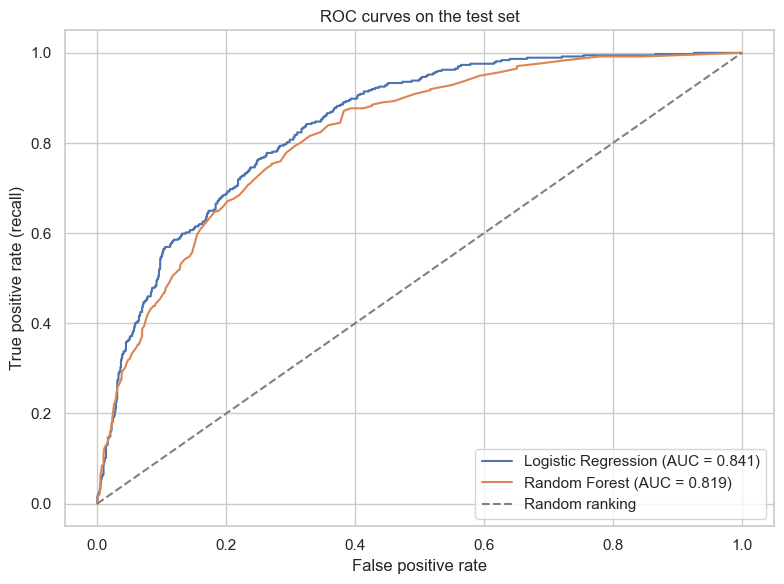

In [18]:
plt.figure(figsize=(8, 6))
for model_name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{model_name} (AUC = {auc_value:.3f})",
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
plt.title("ROC curves on the test set")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.tight_layout()
plt.show()

## Select a preferred model for this exercise

For an initial retention outreach use case, missing likely churners can be costly, while low precision can waste limited outreach resources. This notebook uses F1-score as a simple balance between recall and precision, with recall as the tie-breaker. A real business should choose a threshold using its outreach capacity and the costs and benefits of interventions; this default-threshold comparison is not a production decision.

In [19]:
ranked_results = results_table.sort_values(
    by=["F1-score", "Recall", "ROC-AUC"],
    ascending=False,
)
preferred_model_name = ranked_results.index[0]
preferred_metrics = ranked_results.iloc[0]

print(f"Preferred model by the stated F1/recall rule: {preferred_model_name}")
print(
    "Test results: "
    f"precision={preferred_metrics['Precision']:.3f}, "
    f"recall={preferred_metrics['Recall']:.3f}, "
    f"F1={preferred_metrics['F1-score']:.3f}, "
    f"ROC-AUC={preferred_metrics['ROC-AUC']:.3f}."
)

Preferred model by the stated F1/recall rule: Logistic Regression
Test results: precision=0.504, recall=0.783, F1=0.614, ROC-AUC=0.841.


## Conclusion, limitations, and responsible use

The printed summary below is calculated from this CSV and the held-out test results. The dataset is a historical sample, its variables may not capture current customer circumstances, and the random split is only one evaluation. The models use a default prediction threshold and have not been calibrated, externally validated, or tested in a live business process. Associations and model scores do not explain causes. Any outreach should be proportionate, reviewed by people, and evaluated for fairness and customer impact. Useful future work could include validating on newer data, selecting a decision threshold based on intervention costs, and monitoring performance over time.

In [20]:
highest_contract_rate = contract_churn_rates.index[0]
lowest_contract_rate = contract_churn_rates.index[-1]
print(f"Customers in the dataset: {len(df):,}")
print(f"Observed churn share: {df['Churn'].eq('Yes').mean():.1%}")
print(
    f"Contract groups with the highest and lowest observed churn rates: "
    f"{highest_contract_rate} ({contract_churn_rates.iloc[0]:.1f}%) and "
    f"{lowest_contract_rate} ({contract_churn_rates.iloc[-1]:.1f}%)."
)
print(
    "These contract differences are descriptive associations, not causal effects. "
    f"By the chosen test-set F1/recall rule, {preferred_model_name} ranked first; "
    "see the comparison table for the full metrics and trade-offs."
)

Customers in the dataset: 7,043
Observed churn share: 26.5%
Contract groups with the highest and lowest observed churn rates: Month-to-month (42.7%) and Two year (2.8%).
These contract differences are descriptive associations, not causal effects. By the chosen test-set F1/recall rule, Logistic Regression ranked first; see the comparison table for the full metrics and trade-offs.
